# Lesson 09 · The multinomial and the Dirichlet

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 10 (pp. 89–98)

**Question:** Not all hits are equal: a home run is worth more than a single. Who were the best sluggers in history once we account for small samples?

**Goal:** Move from two outcomes to five (single, double, triple, home run, out), using the multinomial and its conjugate prior, the Dirichlet. Fit a Dirichlet-multinomial prior and shrink slugging percentages.

**Contents**

1. Setup: hit types
2. Slugging percentage, raw
3. The multinomial and the Dirichlet, by simulation
4. Fitting a Dirichlet-multinomial prior
5. Checking the fit
6. Shrinking slugging percentage
7. Exercises

**Tags:** `dirichlet` `multinomial` `dirichlet-multinomial` `slugging-percentage` `pseudo-counts` `maximum-likelihood`

**Before you start:** Lessons 01–02.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [1]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

hits = eb_data.hit_types(pitcher_rule=3)
categories = ["Single", "Double", "Triple", "HR", "NonHit"]
print(f"{len(hits):,} players")
hits.head()

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
13,446 players


,playerID,name,AB,H,Single,Double,Triple,HR,NonHit
0,aaronha01,Hank Aaron,12364,3771,2294,624,98,755,8593
1,aaronto01,Tommie Aaron,944,216,155,42,6,13,728
2,abadan01,Andy Abad,21,2,2,0,0,0,19
3,abadijo01,John Abadie,49,11,11,0,0,0,38
4,abbated01,Ed Abbaticchio,3044,772,619,99,43,11,2272


## 1. Setup: hit types

**9.1.1 · Your turn.** Confirm that `Single + Double + Triple + HR + NonHit == AB` for every player. Show Hank Aaron's row.

In [2]:
# 9.1.1 · Your code here
(hits.AB == hits.iloc[:, 4:9].sum(axis = 1)).sum() == len(hits)
hits[hits.name == 'Hank Aaron']

,playerID,name,AB,H,Single,Double,Triple,HR,NonHit
0,aaronha01,Hank Aaron,12364,3771,2294,624,98,755,8593


> **Check:** Hank Aaron: 12,364 AB, 2,294 singles, 624 doubles, 98 triples, 755 HR.

## 2. Slugging percentage, raw

$$\text{SLG} = \frac{\text{Singles} + 2\cdot\text{Doubles} + 3\cdot\text{Triples} + 4\cdot\text{HR}}{AB},$$

which ranges from 0 to 4.

**9.2.1 · Your turn.** Compute `slugging` and show the top 8. Then, for players with AB ≥ 500, plot histograms of each hit type as a fraction of AB.

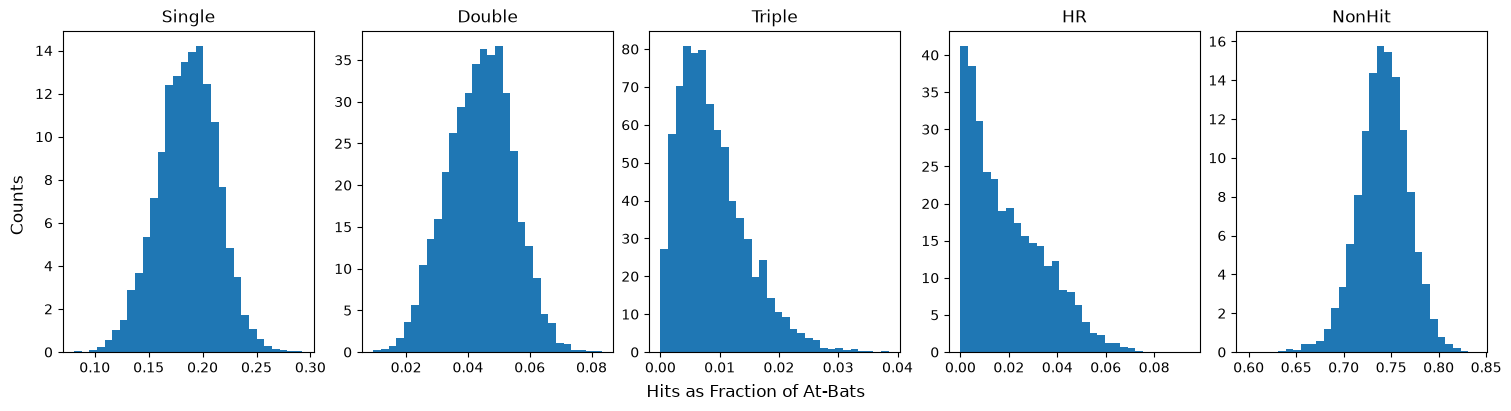

In [3]:
# 9.2.1 · Your code here
hits['slugging'] = (hits.Single + 2 * hits.Double + 3 * hits.Triple + 4 * hits.HR) / hits.AB
hits.sort_values(by = 'slugging', ascending = False).head(8)

hits_500 = hits[hits.AB >= 500]

fig, axes = plt.subplots(1, 5, figsize = (15, 4), layout = "constrained")
for i in np.arange(5):
    axes[i].hist((hits_500[categories[i]]/hits_500.AB), bins = 30, density = True)
    axes[i].set_title(categories[i])
fig.supxlabel("Hits as Fraction of At-Bats")
fig.supylabel("Counts")
plt.show()

**9.2.2 · Reflect.** Who tops the raw slugging list, and why is that the same problem as in Lesson 02?

*9.2.2 · Your answer:*

It's once again populated by noisy low AB batters that either luckily (or maybe really) hit well.

## 3. The multinomial and the Dirichlet, by simulation

Each at-bat is a roll of a five-sided die with probabilities $p_1, \dots, p_5$: a **multinomial**. Its conjugate prior is the **Dirichlet**($\alpha_1, \dots, \alpha_5$):
- the relative sizes $\alpha_k / \sum\alpha$ set where the probability mass goes;
- the total $\sum\alpha$ sets how tightly it concentrates there.

The beta is the two-category special case.

**9.3.1 · Your turn.** Simulate a few multinomial draws with `rng.multinomial(100, [.2] * 5, size=3)` and `rng.multinomial(100, [.05, .05, .2, .2, .5], size=3)`.

In [4]:
# 9.3.1 · Your code here
c = rng.multinomial(100, [.2] * 5, size=3)

d = rng.multinomial(100, [.05, .05, .2, .2, .5], size=3)

print(f"Equal probabilities draw:\n {c},\n Skewed probabilities draw:\n {d}")

Equal probabilities draw:
 [[26 19 21 17 17]
 [13 25 20 20 22]
 [17 21 22 25 15]],
 Skewed probabilities draw:
 [[ 6  8 20 23 43]
 [ 5  4 20 23 48]
 [ 5  5 20 17 53]]


**9.3.2 · Your turn.** Simulate 10,000 Dirichlet draws for (1, 1, 1, 1, 1), (5, 2, 2, 1, 1) and (500, 200, 200, 100, 100) with `rng.dirichlet`. Plot a histogram per category, one row per parameter set (a 3×5 grid).

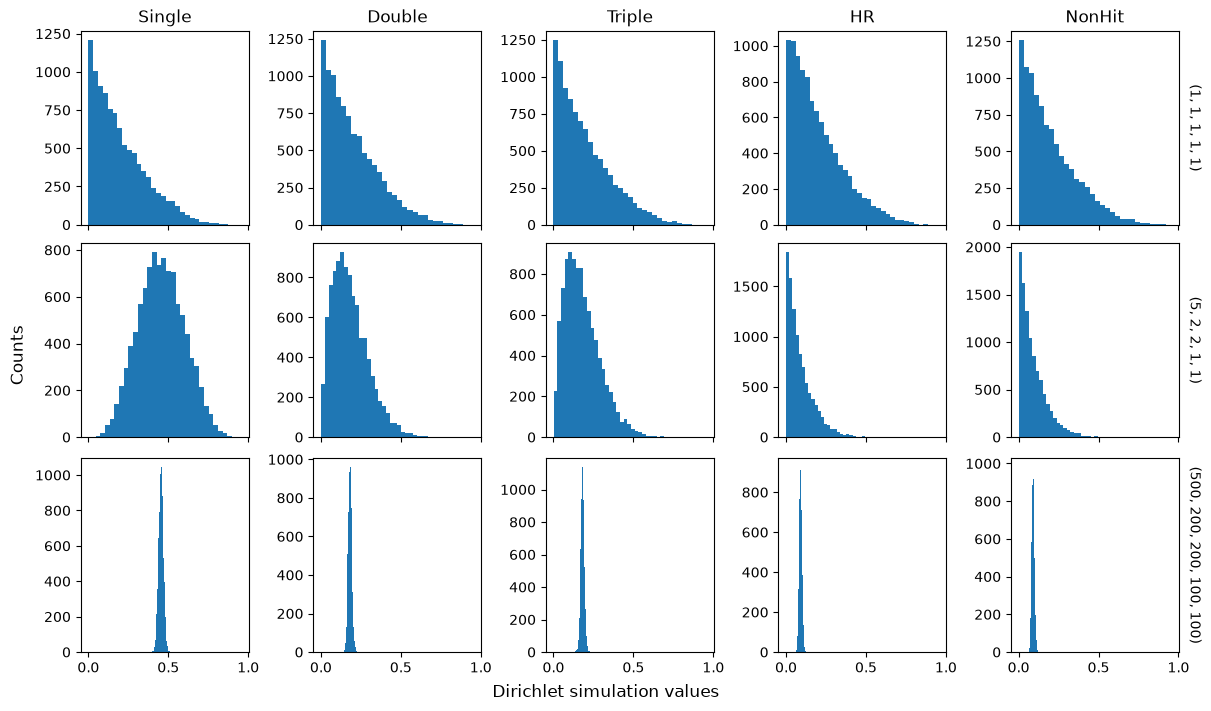

In [5]:
# 9.3.2 · Your code here
draws = []
size = 10000
probs = (1, 1, 1, 1, 1), (5, 2, 2, 1, 1), (500, 200, 200, 100, 100)

for prob in probs:
    draws.append(rng.dirichlet(prob, size))

fig, axes = plt.subplots(3, 5, figsize = (12, 7), sharex = True, layout = 'constrained')

for i in np.arange(len(draws)): # Each probability, 3 total, row designation
    for j in np.arange(0, 5):  # Each outcome, here 5 in total, column designation
        axes[i][j].hist(draws[i][:, j], bins = 30)
    ax = axes[i, -1]
    ax.text(1.05, 0.5, str(probs[i]), transform=ax.transAxes,
        rotation=-90, va="center", ha="left")
for j in np.arange(0, 5):
    axes[0][j].set_title(categories[j])
fig.supxlabel("Dirichlet simulation values")
fig.supylabel("Counts")
plt.show()


**9.3.3 · Reflect.** (5, 2, 2, 1, 1) and (500, 200, 200, 100, 100) have the same means. What's different, and what does the total represent if you think of the α's as pseudo-counts?

*9.3.3 · Your answer:*

## 4. Fitting a Dirichlet-multinomial prior

As in Lesson 02, average over the unknown probabilities. The result is the **Dirichlet-multinomial**, with log-pmf

$$\log P(x \mid \alpha) = \log\Gamma(A) + \log\Gamma(n+1) - \log\Gamma(n + A) + \sum_k \left[\log\Gamma(x_k + \alpha_k) - \log\Gamma(\alpha_k) - \log\Gamma(x_k + 1)\right],$$

where $A = \sum_k \alpha_k$ and $n = \sum_k x_k$. SciPy has `stats.dirichlet_multinomial`, but writing the formula with `special.gammaln` is quick, vectorizes over players, and makes the fit fast.

**9.4.1 · Your turn.** Write `dm_neg_log_lik(log_alpha, X)` for a players × 5 count matrix `X`, then fit the players with AB ≥ 500 (optimize over log α). Check your log-pmf against `stats.dirichlet_multinomial.logpmf` for one player.

In [6]:
# 9.4.1 · Your code here
def dm_neg_log_lik(log_alpha, X):
    alpha = np.exp(log_alpha)
    A = alpha.sum()
    n = X.sum(axis = 1)
    neg_multisum = -((special.gammaln(A) + special.gammaln(n + 1) - special.gammaln(n + A) + 
                     (special.gammaln(X + alpha) - special.gammaln(alpha) - special.gammaln(X + 1)).sum(axis = 1)).sum())
    return neg_multisum

X = (hits_500[categories].to_numpy())

res = optimize.minimize(dm_neg_log_lik, x0 = np.zeros(5), args = (X,))
a1, a2, a3, a4, a5 = np.exp(res.x)
alphas = [a1, a2, a3, a4, a5]
print(alphas)

[np.float64(32.55594811316982), np.float64(7.964970827590877), np.float64(1.703501964702157), np.float64(2.862342989493733), np.float64(129.11255883756402)]


> **Check:** α ≈ Single 35.3, Double 8.42, Triple 1.85, HR 2.84, NonHit 138.

## 5. Checking the fit

Each category's marginal under the Dirichlet is a beta: $p_k \sim \text{Beta}(\alpha_k, A - \alpha_k)$.

**9.5.1 · Your turn.** Overlay each category's fitted beta density on its histogram from Section 2 (AB ≥ 500).

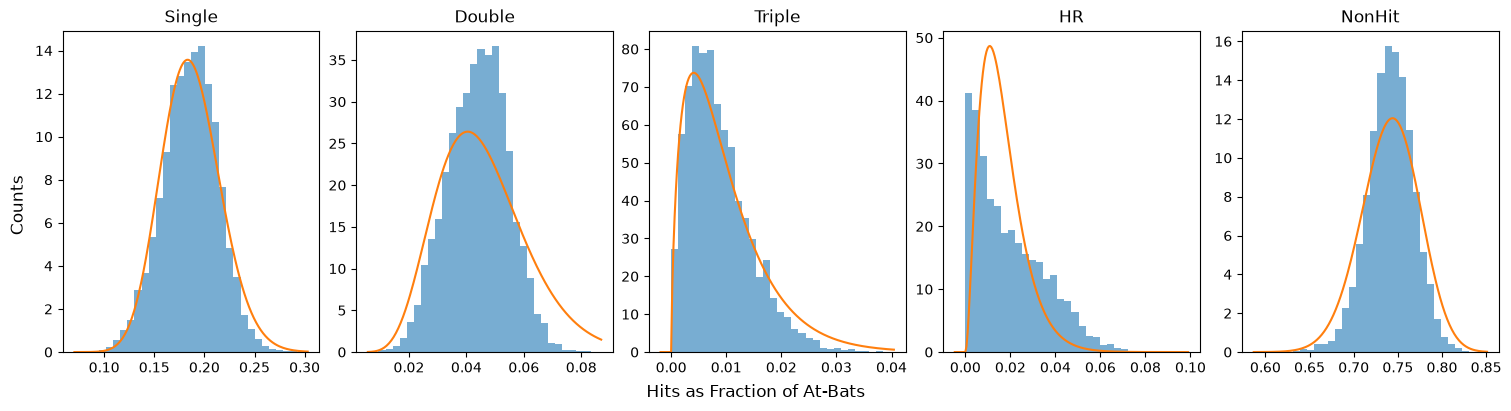

In [7]:
# 9.5.1 · Your code here

fig, axes = plt.subplots(1, 5, figsize = (15, 4), layout = "constrained")
for i in np.arange(5):
    axes[i].hist((hits_500[categories[i]]/hits_500.AB), bins = 30, density = True, alpha = 0.6)
    lo, hi = axes[i].get_xlim()
    x = np.linspace(lo, hi, 200)
    axes[i].plot(x, stats.beta.pdf(x, alphas[i], sum(alphas) - alphas[i]))
    axes[i].set_title(categories[i])
fig.supxlabel("Hits as Fraction of At-Bats")
fig.supylabel("Counts")
plt.show()

**9.5.2 · Reflect.** Which categories does the Dirichlet fit well, and which badly? A Dirichlet has a single total controlling the spread of every category. Why is that a strong assumption?

*9.5.2 · Your answer:*

## 6. Shrinking slugging percentage

Shrinkage is the same pseudo-count trick: add each $\alpha_k$ to its category's count, then compute slugging.

**9.6.1 · Your turn.** Compute the prior mean slugging (weights 1, 2, 3, 4, 0 applied to α / A), then the shrunken `slugging_eb` for every player.

In [8]:
print((((hits[categories] + alphas) * np.array([1, 2, 3, 4, 0])).sum(axis = 1))/hits.AB)


0        0.5598
1        0.3962
2        3.1927
3        1.5520
4        0.3466
          ...  
13441    0.4289
13442    0.4277
13443    3.8359
13444    0.4095
13445    0.4883
Length: 13446, dtype: float64


In [9]:
# 9.6.1 · Your code here
hits['mu_prior'] = [sum(alphas/sum(alphas) * np.array([1, 2, 3, 4, 0]))]*len(hits)
hits.head()
hits['slugging_eb'] =((((hits[categories] + alphas) * np.array([1, 2, 3, 4, 0])).sum(axis = 1))/(hits.AB + sum(alphas)))
hits.head()

,playerID,name,AB,H,Single,Double,Triple,HR,NonHit,slugging,mu_prior,slugging_eb
0,aaronha01,Hank Aaron,12364,3771,2294,624,98,755,8593,0.5545,0.3734,0.5520
1,aaronto01,Tommie Aaron,944,216,155,42,6,13,728,0.3273,0.3734,0.3345
2,abadan01,Andy Abad,21,2,2,0,0,0,19,0.0952,0.3734,0.3435
3,abadijo01,John Abadie,49,11,11,0,0,0,38,0.2245,0.3734,0.3407
4,abbated01,Ed Abbaticchio,3044,772,619,99,43,11,2272,0.3252,0.3734,0.3278


> **Check:** prior mean slugging ≈ 0.370.

**9.6.2 · Your turn.** Plot raw against shrunken slugging, colored by AB, and list the top 10 by `slugging_eb`.

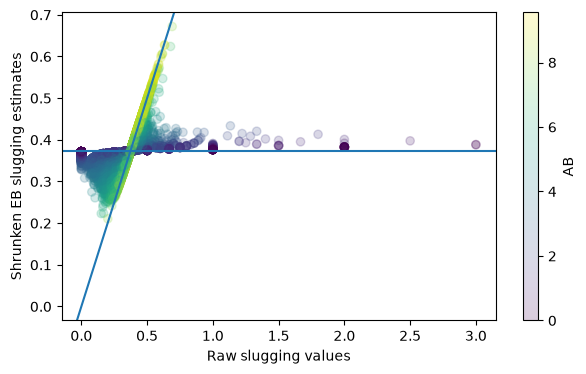

,playerID,name,AB,H,Single,Double,Triple,HR,NonHit,slugging,mu_prior,slugging_eb
4312,gibsojo99,Josh Gibson,2768,1007,568,170,72,197,1761,0.6908,0.3734,0.6720
13059,willite01,Ted Williams,7706,2654,1537,525,71,521,5052,0.6338,0.3734,0.6280
4248,gehrilo01,Lou Gehrig,8001,2721,1531,534,163,493,5280,0.6324,0.3734,0.6269
11223,smithch12,Charlie Smith,805,323,198,67,18,40,482,0.6783,0.3734,0.6240
11538,steartu99,Turkey Stearnes,3959,1372,812,243,122,195,2587,0.6173,0.3734,0.6070
6240,judgeaa01,Aaron Judge,4105,1205,627,203,7,368,2900,0.6153,0.3734,0.6055
1105,bondsba01,Barry Bonds,9847,2935,1495,601,77,762,6912,0.6069,0.3734,0.6028
4644,greenha01,Hank Greenberg,5193,1628,847,379,71,331,3565,0.6050,0.3734,0.5975
7902,mcgwima01,Mark McGwire,6187,1626,785,252,6,583,4561,0.5882,0.3734,0.5823
9842,ramirma02,Manny Ramirez,8244,2574,1452,547,20,555,5670,0.5854,0.3734,0.5810


In [10]:
# 9.6.2 · Your code here
plt.scatter(hits.slugging, hits.slugging_eb, c = np.log(hits.AB), alpha = 0.2)
plt.xlabel("Raw slugging values")
plt.ylabel("Shrunken EB slugging estimates")
plt.axline((0, 0), slope=1)
plt.axhline(sum(alphas * np.array([1, 2, 3, 4, 0])) / sum(alphas))
plt.colorbar(label="AB")
plt.show()
hits.sort_values('slugging_eb', ascending = False).head(10)

> **Check:** Ted Williams, Lou Gehrig and Barry Bonds should lead.

## 7. Exercises

**9.7.1 · Your turn.** Shrink the home-run rate on its own with a beta-binomial (HR vs not-HR). Compare the fitted Beta with the Dirichlet's HR marginal. Should they agree? Do they?

In [11]:
# 9.7.1 · Your code here

**9.7.2 · Reflect.** **Card connection.** Pokémon cards are sold in sealed *booster packs* of about ten random cards, released in *sets*. In many sets, one position in the pack, the *rare slot*, always holds a card from one of several *rarity* tiers (for example rare, double rare, ultra rare, special illustration rare), with the scarcer tiers turning up less often. (That's simplified; real pack layouts vary by set.) If you've logged the rarities pulled from each set, how would a Dirichlet-multinomial help estimate each set's rarity mix? What do the pseudo-counts mean there?

*9.7.2 · Your answer:*

## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 10.
- Minka (2000), "Estimating a Dirichlet distribution" (technical report): fixed-point algorithms for the fit.
- SciPy `dirichlet_multinomial`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.dirichlet_multinomial.html
- Wikipedia, "Conjugate prior" (table of conjugate pairs): https://en.wikipedia.org/wiki/Conjugate_prior